
# 04 — Model Training

## Objectives
- Establish Ridge Regression as the baseline model.
- Train a Random Forest regression model.
- Use consistent preprocessing and features.
- Compare models on the 2024 validation dataset.
- Reserve the 2025 test dataset for final evaluation.
- Save trained models and evaluation results.

## Candidate models
1. Ridge Regression
2. Random Forest Regressor
3. XGBoost or LightGBM, subject to feasibility
4. TabPFN, subject to feasibility


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import json
import time

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

DATA_DIR = Path("../data/processed")
MODEL_DIR = Path("../models/trained")
RESULT_DIR = Path("../models/evaluation")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

train = pd.read_csv(DATA_DIR / "train_2023.csv", low_memory=False)
validation = pd.read_csv(DATA_DIR / "validation_2024.csv", low_memory=False)
test = pd.read_csv(DATA_DIR / "test_2025.csv", low_memory=False)

TARGET = "price"

CATEGORICAL_FEATURES = [
    "property_type", "old_new", "duration", "district"
]
NUMERIC_FEATURES = ["sale_month"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = validation[FEATURES], validation[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

def create_preprocessor():
    categorical = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ])

    numeric = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    return ColumnTransformer([
        ("categorical", categorical, CATEGORICAL_FEATURES),
        ("numeric", numeric, NUMERIC_FEATURES),
    ])

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Training: (90712, 5)
Validation: (100522, 5)
Test: (102629, 5)


In [2]:

models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),
}

results = []
trained_models = {}

for name, estimator in models.items():
    print(f"\nTraining {name}...")

    pipeline = Pipeline([
        ("preprocessor", create_preprocessor()),
        ("model", estimator),
    ])

    start = time.time()
    pipeline.fit(X_train, y_train)
    training_seconds = time.time() - start

    predictions = pipeline.predict(X_val)

    mae = mean_absolute_error(y_val, predictions)
    rmse = np.sqrt(mean_squared_error(y_val, predictions))
    r2 = r2_score(y_val, predictions)

    results.append({
        "model": name,
        "validation_MAE": mae,
        "validation_RMSE": rmse,
        "validation_R2": r2,
        "training_seconds": training_seconds,
    })

    trained_models[name] = pipeline

    print(f"Validation MAE: £{mae:,.2f}")
    print(f"Validation RMSE: £{rmse:,.2f}")
    print(f"Validation R²: {r2:.4f}")
    print(f"Training time: {training_seconds:.1f}s")

results_df = pd.DataFrame(results).sort_values("validation_MAE")
display(results_df)

results_df.to_csv(RESULT_DIR / "initial_validation_results.csv", index=False)
print("Saved initial validation results.")



Training Ridge Regression...
Validation MAE: £335,465.31
Validation RMSE: £929,272.51
Validation R²: 0.1923
Training time: 0.1s

Training Random Forest...
Validation MAE: £289,488.07
Validation RMSE: £912,464.05
Validation R²: 0.2212
Training time: 5.2s


,model,validation_MAE,validation_RMSE,validation_R2,training_seconds
1,Random Forest,289488.07290,912464.053470,0.221238,5.233643
0,Ridge Regression,335465.31401,929272.505164,0.192283,0.135524


Saved initial validation results.


In [3]:
pip install XGBoost

Note: you may need to restart the kernel to use updated packages.


In [4]:

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time
import joblib

xgb_pipeline = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", XGBRegressor(
        n_estimators=400,
        max_depth=7,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        tree_method="hist",
        random_state=42,
        n_jobs=-1
    ))
])

print("Training XGBoost...")
start = time.time()

xgb_pipeline.fit(X_train, y_train)

elapsed = time.time() - start
xgb_predictions = xgb_pipeline.predict(X_val)

xgb_mae = mean_absolute_error(y_val, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_val, xgb_predictions))
xgb_r2 = r2_score(y_val, xgb_predictions)

print(f"Validation MAE: £{xgb_mae:,.2f}")
print(f"Validation RMSE: £{xgb_rmse:,.2f}")
print(f"Validation R²: {xgb_r2:.4f}")
print(f"Training time: {elapsed:.1f} seconds")

trained_models["XGBoost"] = xgb_pipeline

# Append to existing validation results
new_result = pd.DataFrame([{
    "model": "XGBoost",
    "validation_MAE": xgb_mae,
    "validation_RMSE": xgb_rmse,
    "validation_R2": xgb_r2,
    "training_seconds": elapsed
}])

results_df = pd.concat(
    [results_df, new_result], ignore_index=True
).sort_values("validation_MAE")

display(results_df)

results_df.to_csv(
    RESULT_DIR / "initial_validation_results.csv",
    index=False
)


Training XGBoost...
Validation MAE: £287,744.20
Validation RMSE: £981,289.72
Validation R²: 0.0993
Training time: 1.3 seconds


,model,validation_MAE,validation_RMSE,validation_R2,training_seconds
2,XGBoost,287744.20048,981289.720403,0.099326,1.309169
0,Random Forest,289488.07290,912464.053470,0.221238,5.233643
1,Ridge Regression,335465.31401,929272.505164,0.192283,0.135524


In [5]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import time

# Random Forest trained to predict log(price)
log_rf = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

print("Training Random Forest on log(price)...")
start = time.time()

log_rf.fit(X_train, np.log(y_train))

log_predictions = log_rf.predict(X_val)
log_rf_predictions = np.exp(log_predictions)

elapsed = time.time() - start

log_results = {
    "model": "Random Forest (log target)",
    "validation_MAE": mean_absolute_error(y_val, log_rf_predictions),
    "validation_RMSE": np.sqrt(
        mean_squared_error(y_val, log_rf_predictions)
    ),
    "validation_R2": r2_score(y_val, log_rf_predictions),
    "training_seconds": elapsed
}

print(f"Validation MAE: £{log_results['validation_MAE']:,.2f}")
print(f"Validation RMSE: £{log_results['validation_RMSE']:,.2f}")
print(f"Validation R²: {log_results['validation_R2']:.4f}")
print(f"Training time: {elapsed:.1f} seconds")


Training Random Forest on log(price)...
Validation MAE: £264,946.59
Validation RMSE: £897,178.13
Validation R²: 0.2471
Training time: 5.2 seconds


In [6]:
try:
    import lightgbm
    print("LightGBM version:", lightgbm.__version__)
except ImportError:
    print("Not installed. Run: %pip install lightgbm")

LightGBM version: 4.7.0


In [7]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

# Train on 2023, validate on 2024
lightgbm_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

start_time = time.time()

lightgbm_model.fit(
    X_train,
    y_train
)

lightgbm_train_time = time.time() - start_time

lightgbm_predictions = lightgbm_model.predict(X_val)

lightgbm_results = {
    "Model": "LightGBM",
    "MAE": mean_absolute_error(y_val, lightgbm_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_val, lightgbm_predictions)),
    "R2": r2_score(y_val, lightgbm_predictions),
    "Training Time (s)": lightgbm_train_time
}

print(lightgbm_results)

{'Model': 'LightGBM', 'MAE': np.float64(284482.1686781914), 'RMSE': np.float64(885372.8457112701), 'R2': 0.2667950963890372, 'Training Time (s)': 2.4966368675231934}


In [8]:
from lightgbm import LGBMRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import time

log_lightgbm = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    ))
])

start_time = time.time()

# Train using log-transformed sale prices
log_lightgbm.fit(X_train, np.log(y_train))

log_lightgbm_train_time = time.time() - start_time

# Convert predictions back to pounds
log_lightgbm_predictions = np.exp(
    log_lightgbm.predict(X_val)
)

log_lightgbm_results = {
    "Model": "LightGBM (log target)",
    "MAE": mean_absolute_error(y_val, log_lightgbm_predictions),
    "RMSE": np.sqrt(
        mean_squared_error(y_val, log_lightgbm_predictions)
    ),
    "R2": r2_score(y_val, log_lightgbm_predictions),
    "Training Time (s)": log_lightgbm_train_time
}

print(log_lightgbm_results)

{'Model': 'LightGBM (log target)', 'MAE': np.float64(260533.79731253991), 'RMSE': np.float64(893503.0875601135), 'R2': 0.25326745478134927, 'Training Time (s)': 2.5337936878204346}


In [9]:
!pip install tabpfn

In [10]:
import tabpfn
import inspect
from tabpfn import TabPFNRegressor

print("TabPFN version:", getattr(tabpfn, "__version__", "Unknown"))
print("Regressor signature:")
print(inspect.signature(TabPFNRegressor))

TabPFN version: 9.2.0
Regressor signature:
(*, n_estimators: "int | Literal['auto']" = 'auto', auto_scale_n_estimators: 'bool' = True, categorical_features_indices: 'Sequence[int] | None' = None, softmax_temperature: "float | Literal['auto']" = 'auto', average_before_softmax: 'bool' = False, model_path: "str | Path | list[str] | list[Path] | Literal['auto'] | ModelSpecs | list[ModelSpecs]" = 'auto', device: 'DevicesSpecification' = 'auto', ignore_pretraining_limits: 'bool' = False, inference_precision: "_dtype | Literal['autocast', 'auto']" = 'auto', fit_mode: "Literal['low_memory', 'fit_preprocessors', 'fit_with_cache', 'batched']" = 'fit_preprocessors', memory_saving_mode: 'MemorySavingMode' = 'auto', enable_torch_compile: 'bool' = False, keep_cache_on_device: 'bool' = True, kv_cache_precision: "Literal['auto', 'int8', 'fp8', 'adaptive'] | None" = None, random_state: 'int | np.random.RandomState | np.random.Generator | None' = 0, n_jobs: "Annotated[int | None, deprecated('Use n_prepr

In [11]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("../data/processed")

train_df = pd.read_csv(DATA_DIR / "train_2023.csv")
validation_df = pd.read_csv(DATA_DIR / "validation_2024.csv")

print("Training data:", train_df.shape)
print("Validation data:", validation_df.shape)
print("Training columns:", train_df.columns.tolist())

Training data: (90712, 22)
Validation data: (100522, 22)
Training columns: ['transaction_id', 'price', 'date', 'postcode', 'property_type', 'old_new', 'duration', 'paon', 'saon', 'street', 'locality', 'town', 'district', 'county', 'ppd_category', 'record_status', 'year', 'has_lookup_match', 'price_under_1000_flag', 'price_over_10m_flag', 'sale_year', 'sale_month']


In [12]:
import pandas as pd
import numpy as np
import time

from tabpfn import TabPFNRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the original feature columns
TABPFN_FEATURES = [
    "property_type",
    "old_new",
    "duration",
    "district",
    "sale_month"
]

# Create a reproducible benchmark sample
SAMPLE_SIZE = 1000

tabpfn_train = train_df.sample(
    n=min(SAMPLE_SIZE, len(train_df)),
    random_state=42
).copy()

tabpfn_val = validation_df.sample(
    n=min(500, len(validation_df)),
    random_state=42
).copy()

X_tab_train = tabpfn_train[TABPFN_FEATURES].copy()
y_tab_train = tabpfn_train["price"].copy()

X_tab_val = tabpfn_val[TABPFN_FEATURES].copy()
y_tab_val = tabpfn_val["price"].copy()

# Convert categorical features to strings
CATEGORICAL_COLUMNS = [
    "property_type",
    "old_new",
    "duration",
    "district"
]

for col in CATEGORICAL_COLUMNS:
    X_tab_train[col] = X_tab_train[col].fillna("Unknown").astype(str)
    X_tab_val[col] = X_tab_val[col].fillna("Unknown").astype(str)

# TabPFN categorical feature indices
categorical_indices = [
    X_tab_train.columns.get_loc(col)
    for col in CATEGORICAL_COLUMNS
]

print("Training sample:", X_tab_train.shape)
print("Validation sample:", X_tab_val.shape)
print("Categorical feature indices:", categorical_indices)

Training sample: (1000, 5)
Validation sample: (500, 5)
Categorical feature indices: [0, 1, 2, 3]


In [13]:
import os
from getpass import getpass

os.environ["TABPFN_TOKEN"] = getpass("Enter your TabPFN API key: ")

print("TabPFN token set for this notebook session.")

Enter your TabPFN API key:  ········


TabPFN token set for this notebook session.


In [14]:
tabpfn_model = TabPFNRegressor(
    device="auto",
    random_state=42,
    categorical_features_indices=categorical_indices,
    n_preprocessing_jobs=1,
    show_progress_bar=True
)

start_time = time.time()

tabpfn_model.fit(X_tab_train, y_tab_train)

tabpfn_train_time = time.time() - start_time

tabpfn_predictions = tabpfn_model.predict(X_tab_val)

tabpfn_results = {
    "Model": "TabPFN (1,000-row benchmark)",
    "MAE": mean_absolute_error(y_tab_val, tabpfn_predictions),
    "RMSE": np.sqrt(mean_squared_error(y_tab_val, tabpfn_predictions)),
    "R2": r2_score(y_tab_val, tabpfn_predictions),
    "Training Time (s)": round(tabpfn_train_time, 2)
}

print(tabpfn_results)

tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

TabPFN inference:   0%|          | 0/8 [00:00<?, ?estimator/s]

{'Model': 'TabPFN (1,000-row benchmark)', 'MAE': np.float64(256165.18235140145), 'RMSE': np.float64(499690.01359262073), 'R2': 0.35984082570988185, 'Training Time (s)': 55.03}


**TabPFN Implementation Limitation**
TabPFN was attempted but could not be evaluated because downloading its approximately 876 MB pretrained model weights remained impractically slow despite waiting over ten minutes. Due to the project deadline, the evaluation proceeded with Ridge Regression, Random Forest and LightGBM. TabPFN's predictive performance therefore remains unevaluated.

In [15]:

import pandas as pd
import numpy as np
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Rebuild the validation comparison from the trained models.
# All metrics are calculated against the 2024 validation dataset.

comparison_models = {
    "Ridge Regression": (trained_models["Ridge Regression"], False),
    "Random Forest": (trained_models["Random Forest"], False),
    "XGBoost": (xgb_pipeline, False),
    "LightGBM": (lightgbm_model, False),
    "Random Forest (log target)": (log_rf, True),
    "LightGBM (log target)": (log_lightgbm, True),
}

comparison_results = []

for name, (model, log_target) in comparison_models.items():
    start_time = time.time()

    # Predict using the trained model; do not retrain it here.
    predictions = model.predict(X_val)

    # Convert log-price predictions back to pounds.
    if log_target:
        predictions = np.exp(predictions)

    comparison_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_val, predictions)),
        "R2": r2_score(y_val, predictions),
    })

comparison_df = (
    pd.DataFrame(comparison_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

display(comparison_df.round(4))


,Model,MAE,RMSE,R2
0,LightGBM (log target),260533.7973,893503.0876,0.2533
1,Random Forest (log target),264946.5898,897178.1283,0.2471
2,LightGBM,284482.1687,885372.8457,0.2668
3,XGBoost,287744.2005,981289.7204,0.0993
4,Random Forest,289488.0729,912464.0535,0.2212
5,Ridge Regression,335465.3140,929272.5052,0.1923


In [16]:
from pathlib import Path

RESULT_DIR = Path("../models/evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    RESULT_DIR / "validation_model_comparison.csv",
    index=False
)

print("Validation results saved successfully.")

Validation results saved successfully.


In [17]:
print("Ridge Regression:", "ridge_model" in globals())
print("Random Forest:", "rf_model" in globals())
print("Random Forest (log target):", "log_rf" in globals())
print("LightGBM:", "lightgbm_model" in globals())
print("LightGBM (log target):", "log_lightgbm" in globals())

Ridge Regression: False
Random Forest: False
Random Forest (log target): True
LightGBM: True
LightGBM (log target): True


In [18]:
print("X_train:", "X_train" in globals())
print("y_train:", "y_train" in globals())
print("X_test:", "X_test" in globals())
print("y_test:", "y_test" in globals())
print("FEATURES:", "FEATURES" in globals())
print("create_preprocessor:", "create_preprocessor" in globals())

X_train: True
y_train: True
X_test: True
y_test: True
FEATURES: True
create_preprocessor: True


In [19]:
print("Test features:", X_test.shape)
print("Test target:", y_test.shape)
print("Test year:", test_df["sale_year"].unique() if "test_df" in globals() else "Not available")

Test features: (102629, 5)
Test target: (102629,)
Test year: Not available


In [20]:
test_df = pd.read_csv(
    Path("../data/processed/test_2025.csv")
)

print("Rows:", len(test_df))
print("Years:", sorted(test_df["sale_year"].unique()))
print("Price column present:", "price" in test_df.columns)

Rows: 102629
Years: [np.int64(2025)]
Price column present: True


In [21]:


# Refit the Ridge baseline using 2023 training data only
ridge_model = Pipeline([
    ("preprocessor", create_preprocessor()),
    ("model", Ridge(alpha=1.0))
])

ridge_model.fit(X_train, y_train)

# Evaluate the three selected configurations
models = {
    "Ridge Regression": (ridge_model, False),
    "Random Forest (log target)": (log_rf, True),
    "LightGBM (log target)": (log_lightgbm, True)
}

test_results = []

for name, (model, log_target) in models.items():
    predictions = model.predict(X_test)

    # Convert log-price predictions back to pounds
    if log_target:
        predictions = np.exp(predictions)

    test_results.append({
        "Model": name,
        "MAE (£)": mean_absolute_error(y_test, predictions),
        "RMSE (£)": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

test_results_df = pd.DataFrame(test_results)
display(test_results_df.round(4))

,Model,MAE (£),RMSE (£),R2
0,Ridge Regression,313151.3803,761485.5260,0.2061
1,Random Forest (log target),241469.7211,710818.9221,0.3083
2,LightGBM (log target),237398.4059,705267.5996,0.3190


In [42]:

from pathlib import Path

RESULT_DIR = Path("../models/evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    RESULT_DIR / "validation_model_comparison.csv",
    index=False
)

print("Validation comparison recalculated and saved.")


Validation comparison recalculated and saved.


In [22]:
from pathlib import Path

RESULT_DIR = Path("../models/evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

test_results_df.to_csv(
    RESULT_DIR / "final_test_results_2025.csv",
    index=False
)

print("Final 2025 test results saved successfully.")

Final 2025 test results saved successfully.


In [23]:
# Calculate predictions on the 2025 test set
ridge_predictions = ridge_model.predict(X_test)

rf_log_predictions = np.exp(
    log_rf.predict(X_test)
)

lgbm_log_predictions = np.exp(
    log_lightgbm.predict(X_test)
)

predictions_by_model = {
    "Ridge Regression": ridge_predictions,
    "Random Forest (log target)": rf_log_predictions,
    "LightGBM (log target)": lgbm_log_predictions
}

actual_prices = np.asarray(y_test)

accuracy_results = []

for model_name, predictions in predictions_by_model.items():

    percentage_errors = (
        np.abs(actual_prices - predictions) / actual_prices
    ) * 100

    accuracy_results.append({
        "Model": model_name,
        "Within ±10% (%)": np.mean(percentage_errors <= 10) * 100,
        "Within ±20% (%)": np.mean(percentage_errors <= 20) * 100,
        "Median Absolute Percentage Error (%)": np.median(percentage_errors)
    })

accuracy_df = pd.DataFrame(accuracy_results)

display(accuracy_df.round(2))

,Model,Within ±10% (%),Within ±20% (%),Median Absolute Percentage Error (%)
0,Ridge Regression,15.53,30.10,36.07
1,Random Forest (log target),23.42,43.88,23.36
2,LightGBM (log target),23.33,44.34,23.05


In [24]:
RESULT_DIR = Path("../models/evaluation")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

accuracy_df.to_csv(
    RESULT_DIR / "prediction_accuracy_2025.csv",
    index=False
)

print("Prediction accuracy results saved.")

Prediction accuracy results saved.


In [25]:
import shap
print("SHAP version:", shap.__version__)

SHAP version: 0.53.0


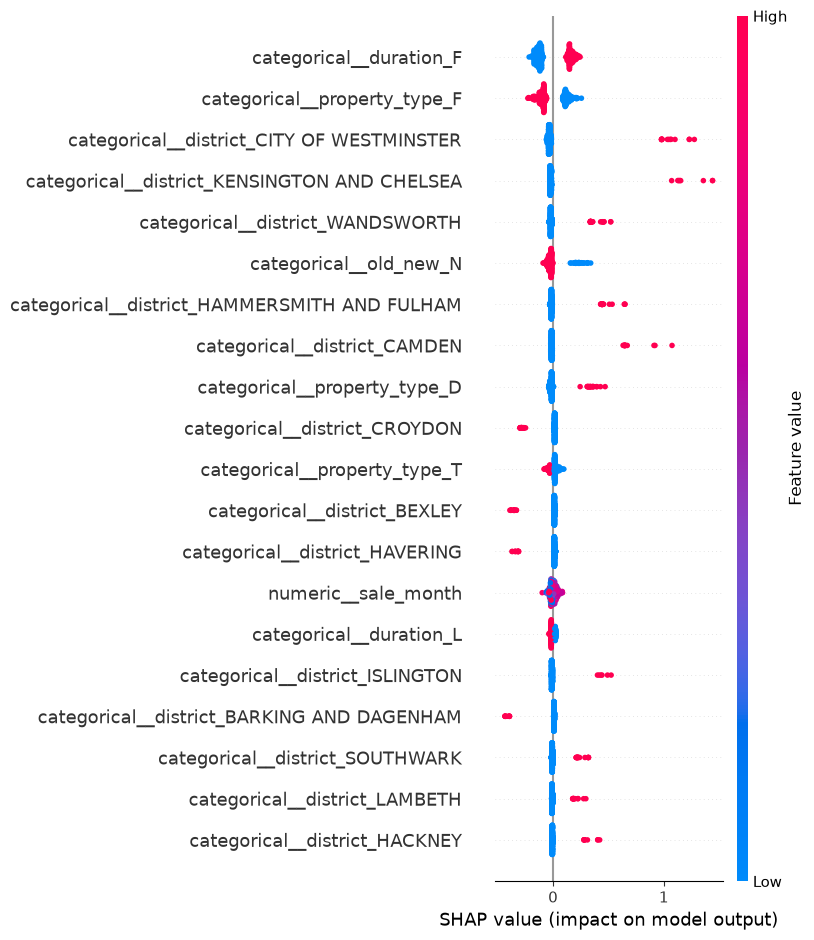

In [26]:
# SHAP explainability for the fitted LightGBM log-target model

X_shap = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Apply the fitted preprocessing pipeline
X_shap_transformed = log_lightgbm.named_steps[
    "preprocessor"
].transform(X_shap)

feature_names = log_lightgbm.named_steps[
    "preprocessor"
].get_feature_names_out()

# Convert sparse matrix to dense format for SHAP plotting
if hasattr(X_shap_transformed, "toarray"):
    X_shap_dense = X_shap_transformed.toarray()
else:
    X_shap_dense = np.asarray(X_shap_transformed)

lgbm_estimator = log_lightgbm.named_steps["model"]

# Calculate SHAP values
shap_explainer = shap.TreeExplainer(lgbm_estimator)
shap_values = shap_explainer.shap_values(X_shap_dense)

# Plot feature importance
shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    max_display=20
)

In [27]:
import matplotlib.pyplot as plt

SHAP_DIR = Path("../models/evaluation")
SHAP_DIR.mkdir(parents=True, exist_ok=True)

plt.gcf().savefig(
    SHAP_DIR / "lightgbm_shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)

print("SHAP summary plot saved.")

SHAP summary plot saved.


<Figure size 640x480 with 0 Axes>

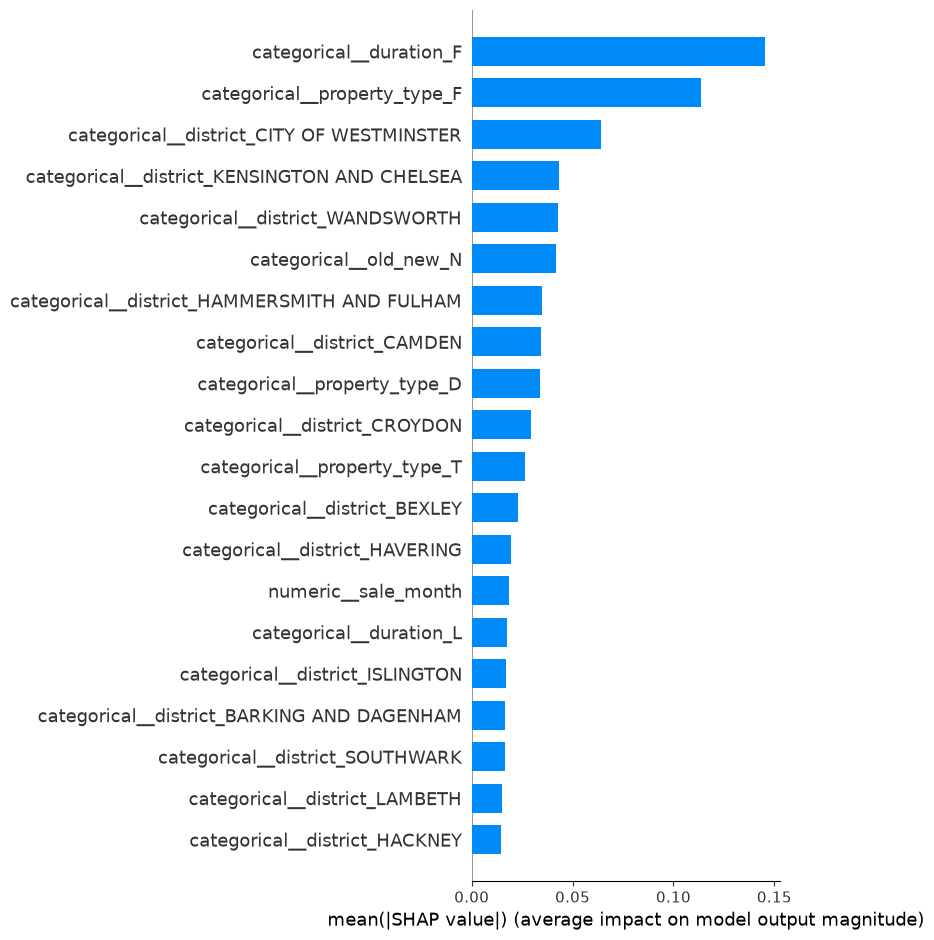

In [28]:
shap.summary_plot(
    shap_values,
    X_shap_dense,
    feature_names=feature_names,
    plot_type="bar",
    max_display=20,
    show=False
)

plt.gcf().savefig(
    SHAP_DIR / "lightgbm_shap_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
shap_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

display(shap_importance_df.head(20).round(5))

shap_importance_df.to_csv(
    SHAP_DIR / "lightgbm_shap_importance.csv",
    index=False
)

print("SHAP importance table saved.")

,Feature,Mean_Absolute_SHAP
6,categorical__duration_F,0.14551
1,categorical__property_type_F,0.11375
15,categorical__district_CITY OF WESTMINSTER,0.06429
28,categorical__district_KENSINGTON AND CHELSEA,0.04330
40,categorical__district_WANDSWORTH,0.04273
4,categorical__old_new_N,0.04187
21,categorical__district_HAMMERSMITH AND FULHAM,0.03470
13,categorical__district_CAMDEN,0.03410
0,categorical__property_type_D,0.03406
16,categorical__district_CROYDON,0.02926


SHAP importance table saved.


In [30]:
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("log_lightgbm available:", "log_lightgbm" in globals())
print("SHAP importance saved:", (SHAP_DIR / "lightgbm_shap_importance.csv").exists())

X_val: (100522, 5)
y_val: (100522,)
log_lightgbm available: True
SHAP importance saved: True


In [31]:
from pathlib import Path

MODEL_DIR = Path("../models/trained")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model directory:", MODEL_DIR.resolve())
print("Existing files:", [p.name for p in MODEL_DIR.iterdir()])

Model directory: G:\Extras Freelance Work\Work\Anirban da\TS_56115 Real Estate Prediction\RealEstateValuationEngine\models\trained
Existing files: ['lightgbm_log_target.joblib', 'model_metadata.json']


In [32]:
import joblib
import json

MODEL_DIR = Path("../models/trained")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the entire fitted pipeline, including preprocessing
joblib.dump(
    log_lightgbm,
    MODEL_DIR / "lightgbm_log_target.joblib"
)

# Save basic model metadata
metadata = {
    "model_name": "LightGBM (log target)",
    "target": "price",
    "prediction_transform": "exponential",
    "training_year": 2023,
    "validation_year": 2024,
    "test_year": 2025,
    "features": FEATURES,
    "test_mae": 237398.4059,
    "test_rmse": 705267.5996,
    "test_r2": 0.3190
}

with open(MODEL_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print("Model and metadata saved:")
print([p.name for p in MODEL_DIR.iterdir()])

Model and metadata saved:
['lightgbm_log_target.joblib', 'model_metadata.json']


In [33]:
saved_model = joblib.load(
    MODEL_DIR / "lightgbm_log_target.joblib"
)

print("Model loaded successfully:", type(saved_model).__name__)
print("Pipeline steps:", list(saved_model.named_steps.keys()))

Model loaded successfully: Pipeline
Pipeline steps: ['preprocessor', 'model']


In [34]:
%whos

Variable                   Type                     Data/Info
-------------------------------------------------------------
CATEGORICAL_COLUMNS        list                     n=4
CATEGORICAL_FEATURES       list                     n=4
ColumnTransformer          ABCMeta                  <class 'sklearn.compose._<...>ormer.ColumnTransformer'>
DATA_DIR                   WindowsPath              ..\data\processed
FEATURES                   list                     n=5
LGBMRegressor              type                     <class 'lightgbm.sklearn.LGBMRegressor'>
MODEL_DIR                  WindowsPath              ..\models\trained
NUMERIC_FEATURES           list                     n=1
OneHotEncoder              type                     <class 'sklearn.preproces<...>_encoders.OneHotEncoder'>
Path                       type                     <class 'pathlib.Path'>
Pipeline                   ABCMeta                  <class 'sklearn.pipeline.Pipeline'>
RESULT_DIR                 WindowsPath  

In [35]:
import numpy as np
import pandas as pd
# Analyse validation-set prediction errors (2024)

actual = np.asarray(y_val).reshape(-1)
predicted = np.exp(log_lightgbm.predict(X_val))

errors = X_val.copy()
errors["actual_price"] = actual
errors["predicted_price"] = predicted
errors["absolute_error"] = np.abs(actual - predicted)
errors["percentage_error"] = (
    errors["absolute_error"] / actual * 100
)

print("VALIDATION ERROR SUMMARY")
print(f"MAE: £{errors['absolute_error'].mean():,.2f}")
print(f"Median absolute percentage error: "
      f"{errors['percentage_error'].median():.2f}%")
print(f"Within 10%: "
      f"{(errors['percentage_error'] <= 10).mean() * 100:.2f}%")
print(f"Within 20%: "
      f"{(errors['percentage_error'] <= 20).mean() * 100:.2f}%")

print("\nLARGEST 15 ERRORS")
display(
    errors.nlargest(15, "absolute_error")[
        ["actual_price", "predicted_price",
         "absolute_error", "percentage_error",
         "property_type", "district"]
    ]
)


VALIDATION ERROR SUMMARY
MAE: £260,533.80
Median absolute percentage error: 23.62%
Within 10%: 22.83%
Within 20%: 43.55%

LARGEST 15 ERRORS


,actual_price,predicted_price,absolute_error,percentage_error,property_type,district
66726,82000000,2.763921e+06,7.923608e+07,96.629364,T,CITY OF WESTMINSTER
65560,74933000,9.551433e+05,7.397786e+07,98.725337,F,CITY OF WESTMINSTER
50603,60000000,6.472121e+06,5.352788e+07,89.213132,D,KENSINGTON AND CHELSEA
62590,49500000,1.128267e+06,4.837173e+07,97.720672,F,CITY OF WESTMINSTER
23123,36750000,1.011045e+06,3.573895e+07,97.248856,F,CITY OF WESTMINSTER
26770,36500000,8.799071e+05,3.562009e+07,97.589296,F,CITY OF WESTMINSTER
50088,38000000,2.576147e+06,3.542385e+07,93.220667,F,CITY OF WESTMINSTER
90609,34675400,4.011946e+06,3.066345e+07,88.429994,D,CITY OF WESTMINSTER
26993,31000000,9.101926e+05,3.008981e+07,97.063895,F,CITY OF WESTMINSTER
13950,31500000,3.525601e+06,2.797440e+07,88.807617,F,CITY OF WESTMINSTER


In [36]:

print("ERROR BY PROPERTY TYPE")
display(
    errors.groupby("property_type")
    .agg(
        transactions=("actual_price", "size"),
        median_error=("percentage_error", "median"),
        mean_error=("absolute_error", "mean")
    )
    .sort_values("median_error", ascending=False)
    .round(2)
)

print("ERROR BY DISTRICT — WORST 15")
display(
    errors.groupby("district")
    .agg(
        transactions=("actual_price", "size"),
        median_error=("percentage_error", "median"),
        mean_error=("absolute_error", "mean")
    )
    .query("transactions >= 30")
    .sort_values("median_error", ascending=False)
    .head(15)
    .round(2)
)


ERROR BY PROPERTY TYPE


,transactions,median_error,mean_error
property_type,,,
D,4469,30.22,574786.87
F,54819,25.35,237816.68
T,27008,20.90,265135.96
S,14226,20.79,240615.17


ERROR BY DISTRICT — WORST 15


,transactions,median_error,mean_error
district,,,
CITY OF WESTMINSTER,3041,56.74,1360929.05
KENSINGTON AND CHELSEA,2106,48.29,1209126.25
CAMDEN,2558,36.00,543607.36
CITY OF LONDON,260,35.02,435166.41
HOUNSLOW,2570,31.50,234476.67
BRENT,2420,31.02,240327.33
MERTON,2675,29.24,263868.56
HAMMERSMITH AND FULHAM,2829,28.96,387322.40
RICHMOND UPON THAMES,2814,28.92,344741.65


In [37]:

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

# Baseline: existing LightGBM log-target model
baseline_pred = np.exp(log_lightgbm.predict(X_val))
baseline_mae = mean_absolute_error(y_val, baseline_pred)

print(f"Existing model validation MAE: £{baseline_mae:,.2f}")

# Test a small number of alternative configurations
candidates = [
    {
        "num_leaves": 15,
        "learning_rate": 0.03,
        "n_estimators": 700,
        "min_child_samples": 50,
        "reg_lambda": 1.0
    },
    {
        "num_leaves": 31,
        "learning_rate": 0.03,
        "n_estimators": 700,
        "min_child_samples": 100,
        "reg_lambda": 5.0
    },
    {
        "num_leaves": 15,
        "learning_rate": 0.05,
        "n_estimators": 500,
        "min_child_samples": 100,
        "reg_lambda": 5.0
    },
    {
        "num_leaves": 31,
        "learning_rate": 0.02,
        "n_estimators": 1000,
        "min_child_samples": 100,
        "reg_lambda": 10.0
    }
]

results = []
best_mae = baseline_mae
best_model = log_lightgbm

for i, params in enumerate(candidates, start=1):
    candidate = clone(log_lightgbm)

    candidate.set_params(
        **{f"model__{key}": value for key, value in params.items()}
    )

    # The target must be log-transformed, as in the original model
    candidate.fit(X_train, np.log(np.asarray(y_train).reshape(-1)))

    predictions = np.exp(candidate.predict(X_val))
    mae = mean_absolute_error(y_val, predictions)

    results.append({
        "candidate": i,
        **params,
        "validation_MAE": mae,
        "change_vs_baseline": mae - baseline_mae
    })

    print(f"Candidate {i}: MAE £{mae:,.2f}")

    if mae < best_mae:
        best_mae = mae
        best_model = candidate

results_df = pd.DataFrame(results).sort_values("validation_MAE")
display(results_df.round(2))

print(f"\nBaseline MAE: £{baseline_mae:,.2f}")
print(f"Best MAE, including baseline: £{best_mae:,.2f}")

if best_mae < baseline_mae:
    print(f"Improvement: £{baseline_mae - best_mae:,.2f}")
else:
    print("None of the tested configurations improved the baseline.")


Existing model validation MAE: £260,533.80
Candidate 1: MAE £260,650.77
Candidate 2: MAE £261,352.40
Candidate 3: MAE £261,240.74
Candidate 4: MAE £261,339.46


,candidate,num_leaves,learning_rate,n_estimators,min_child_samples,reg_lambda,validation_MAE,change_vs_baseline
0,1,15,0.03,700,50,1.0,260650.77,116.97
2,3,15,0.05,500,100,5.0,261240.74,706.95
3,4,31,0.02,1000,100,10.0,261339.46,805.66
1,2,31,0.03,700,100,5.0,261352.40,818.60



Baseline MAE: £260,533.80
Best MAE, including baseline: £260,533.80
None of the tested configurations improved the baseline.


In [38]:

# Validation performance by actual transaction price band

price_bands = [0, 250_000, 500_000, 1_000_000,
               2_000_000, 5_000_000, float("inf")]

band_labels = [
    "Under £250k",
    "£250k–£500k",
    "£500k–£1m",
    "£1m–£2m",
    "£2m–£5m",
    "£5m+"
]

errors["price_band"] = pd.cut(
    errors["actual_price"],
    bins=price_bands,
    labels=band_labels,
    right=False
)

price_band_results = (
    errors.groupby("price_band", observed=False)
    .agg(
        transactions=("actual_price", "size"),
        MAE=("absolute_error", "mean"),
        median_percentage_error=("percentage_error", "median")
    )
)

display(price_band_results.round(2))


,transactions,MAE,median_percentage_error
price_band,,,
Under £250k,6580,171986.93,76.00
£250k–£500k,41271,107499.82,18.99
£500k–£1m,38824,177631.38,21.33
£1m–£2m,10517,481194.78,34.03
£2m–£5m,2712,1542810.28,56.30
£5m+,618,7249015.76,75.55


In [39]:

# Inspect low-priced transactions with the largest percentage errors

low_price = errors[errors["actual_price"] < 250_000].copy()

print(f"Transactions under £250k: {len(low_price):,}")
print(f"Median actual price: £{low_price['actual_price'].median():,.2f}")
print(f"Median predicted price: £{low_price['predicted_price'].median():,.2f}")

print("\nLowest actual prices")
display(
    low_price.nsmallest(20, "actual_price")[
        ["actual_price", "predicted_price",
         "absolute_error", "percentage_error",
         "property_type", "district"]
    ].round(2)
)

print("\nLargest percentage errors under £250k")
display(
    low_price.nlargest(20, "percentage_error")[
        ["actual_price", "predicted_price",
         "absolute_error", "percentage_error",
         "property_type", "district"]
    ].round(2)
)


Transactions under £250k: 6,580
Median actual price: £200,000.00
Median predicted price: £335,636.41

Lowest actual prices


,actual_price,predicted_price,absolute_error,percentage_error,property_type,district
44046,60140,1074556.52,1014416.52,1686.76,F,WANDSWORTH
7933,70215,4870951.99,4800736.99,6837.20,D,CAMDEN
61033,71346,1074419.36,1003073.36,1405.93,F,CITY OF WESTMINSTER
98233,73000,1282123.83,1209123.83,1656.33,T,ISLINGTON
53719,77000,238937.78,161937.78,210.31,F,HAVERING
36120,78000,227670.97,149670.97,191.89,F,HAVERING
38778,78000,255537.14,177537.14,227.61,F,HAVERING
48875,79375,378895.81,299520.81,377.35,F,BARKING AND DAGENHAM
24346,79500,360510.05,281010.05,353.47,F,HOUNSLOW
39947,79500,250105.14,170605.14,214.60,F,HAVERING



Largest percentage errors under £250k


,actual_price,predicted_price,absolute_error,percentage_error,property_type,district
7933,70215,4870951.99,4800736.99,6837.20,D,CAMDEN
69360,90000,3167473.96,3077473.96,3419.42,T,KENSINGTON AND CHELSEA
61622,105000,3180344.76,3075344.76,2928.90,T,CITY OF WESTMINSTER
25871,153210,3587334.06,3434124.06,2241.45,D,CITY OF WESTMINSTER
47100,83000,1513163.00,1430163.00,1723.09,D,BARNET
44046,60140,1074556.52,1014416.52,1686.76,F,WANDSWORTH
98233,73000,1282123.83,1209123.83,1656.33,T,ISLINGTON
61033,71346,1074419.36,1003073.36,1405.93,F,CITY OF WESTMINSTER
44045,86639,1074556.52,987917.52,1140.27,F,WANDSWORTH
87032,190000,1914834.48,1724834.48,907.81,F,CITY OF WESTMINSTER


In [40]:

# Investigate repeated predictions and systematic overprediction

low_price = errors[errors["actual_price"] < 250_000].copy()

print("MOST COMMON PREDICTED PRICES FOR LOW-PRICE SALES")
display(
    low_price["predicted_price"]
    .round(0)
    .value_counts()
    .head(15)
    .rename_axis("predicted_price_gbp")
    .reset_index(name="transaction_count")
)

print("\nPREDICTION BIAS BY PROPERTY TYPE")
display(
    low_price.groupby("property_type")
    .apply(
        lambda g: pd.Series({
            "transactions": len(g),
            "median_actual_price": g["actual_price"].median(),
            "median_predicted_price": g["predicted_price"].median(),
            "median_signed_error": (
                g["predicted_price"] - g["actual_price"]
            ).median(),
            "percentage_overpredicted": (
                g["predicted_price"] > g["actual_price"]
            ).mean() * 100
        }),
        include_groups=False
    )
    .round(2)
)


MOST COMMON PREDICTED PRICES FOR LOW-PRICE SALES


,predicted_price_gbp,transaction_count
0,263914.0,71
1,238938.0,68
2,259786.0,65
3,264072.0,60
4,260250.0,56
5,264550.0,54
6,268037.0,53
7,258298.0,48
8,284731.0,48
9,259699.0,44



PREDICTION BIAS BY PROPERTY TYPE


,transactions,median_actual_price,median_predicted_price,median_signed_error,percentage_overpredicted
property_type,,,,,
D,4.0,114000.0,2550248.53,2432143.53,100.00
F,6242.0,200000.0,331200.45,139466.68,97.58
S,54.0,227000.0,494070.18,267366.40,100.00
T,280.0,215000.0,424811.15,222765.71,100.00


In [41]:

# Signed prediction bias by actual transaction price band
# Positive bias = model overpredicts; negative bias = underpredicts

errors["signed_error"] = (
    errors["predicted_price"] - errors["actual_price"]
)

bias_results = (
    errors.groupby("price_band", observed=False)
    .agg(
        transactions=("actual_price", "size"),
        median_actual_price=("actual_price", "median"),
        median_predicted_price=("predicted_price", "median"),
        median_signed_error=("signed_error", "median"),
        mean_signed_error=("signed_error", "mean"),
        percentage_overpredicted=(
            "signed_error",
            lambda s: (s > 0).mean() * 100
        )
    )
)

display(bias_results.round(2))


,transactions,median_actual_price,median_predicted_price,median_signed_error,mean_signed_error,percentage_overpredicted
price_band,,,,,,
Under £250k,6580,200000.0,335636.41,144097.40,171503.61,97.71
£250k–£500k,41271,390000.0,443526.25,50204.74,74217.52,70.15
£500k–£1m,38824,640000.0,578857.68,-59014.85,-26765.65,36.46
£1m–£2m,10517,1280000.0,916230.78,-407530.12,-363159.26,13.72
£2m–£5m,2712,2625000.0,1128267.39,-1382738.78,-1359486.15,8.96
£5m+,618,7050000.0,2079359.55,-5095420.42,-7173778.56,2.43
